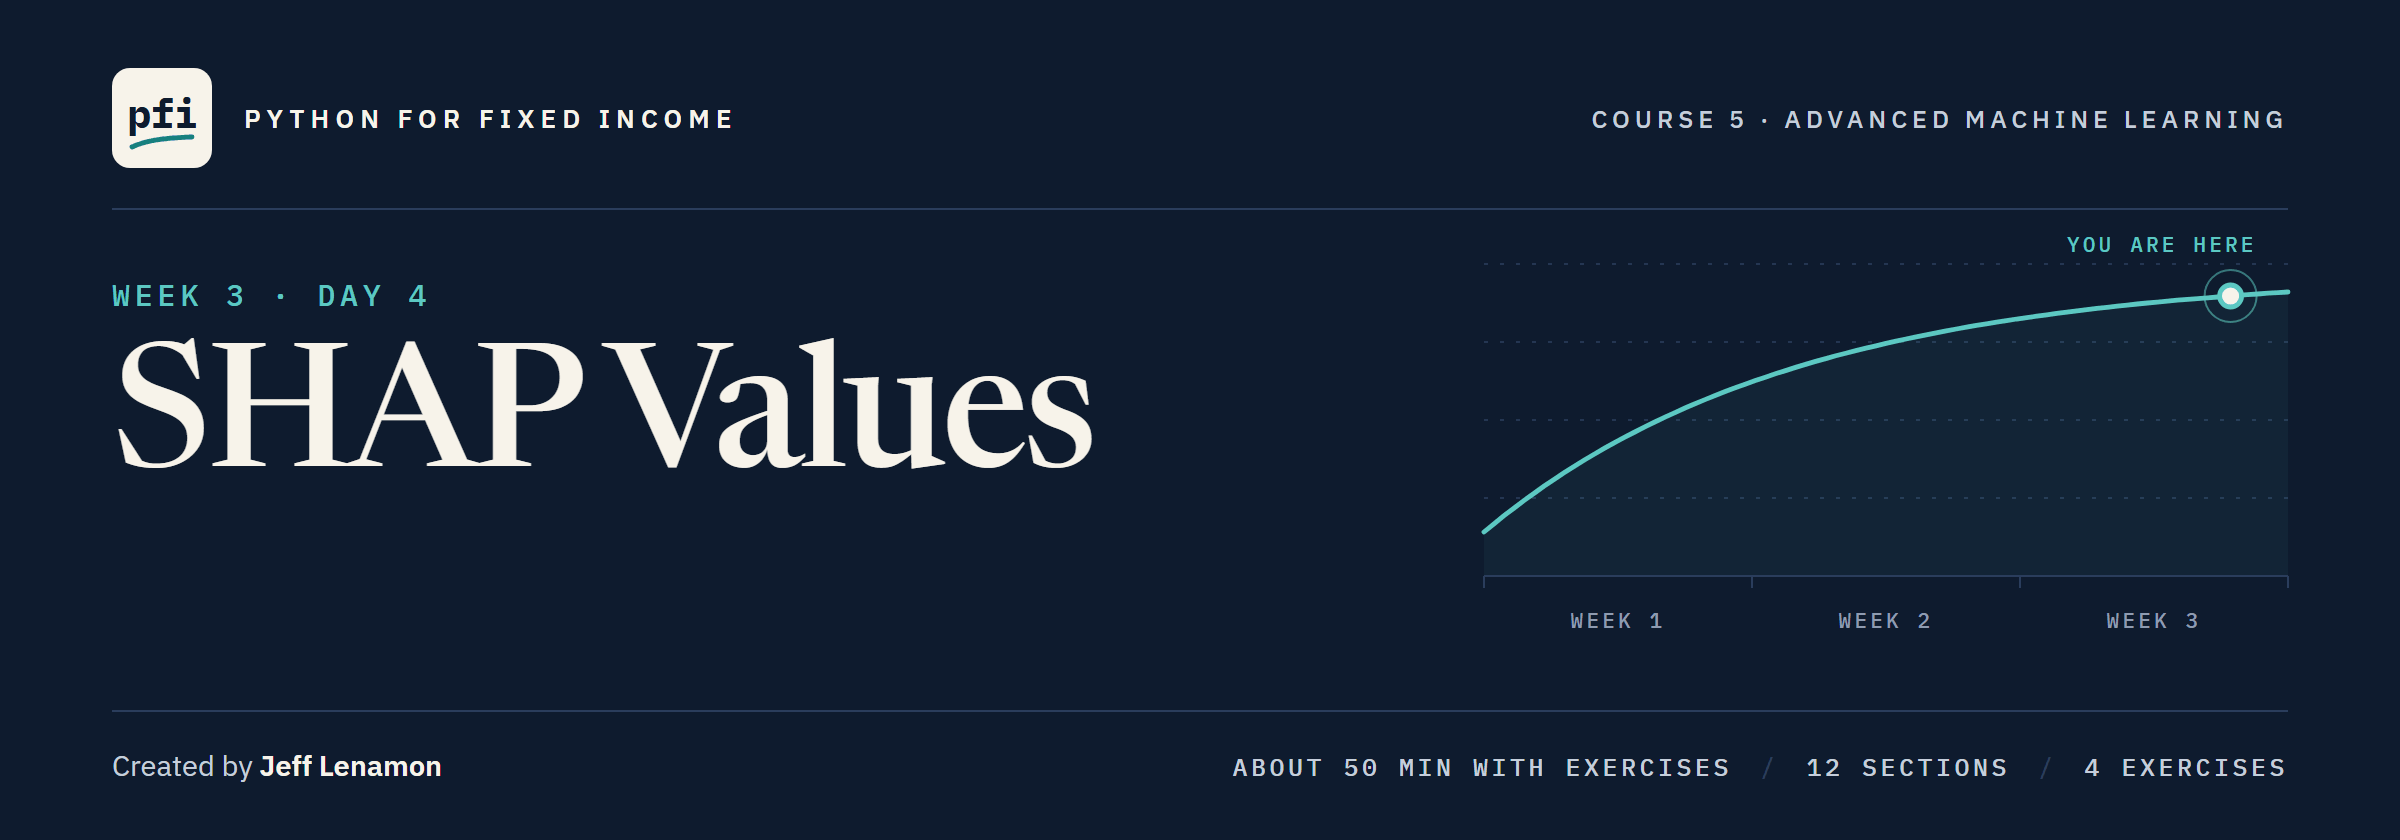

# SHAP Values

Week 3, Day 4. Split one company's model output into a contribution from every column, check that the parts add up, and read what the model leans on, company by company and across the file.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day4/14_shap_values.ipynb)

# Problem Statement

## Business Context

Days 11 to 13 settled a model for the colleague's Polish file: LightGBM at its defaults, unweighted, at a fold average precision of 0.7783.
The file holds financial statements of Polish companies, the bankrupt ones analysed from 2000 to 2012 and the operating ones from 2007 to 2013 ([dataset page](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data)), so it describes one country in one period.
A credit committee now asks the desk two things: for any one company, how does the model arrive at its number, and which columns does it lean on overall?
SHAP values answer both, by splitting each company's output into one contribution per column.
A SHAP value is a column's contribution to this company's log-odds, relative to the model's average log-odds, never a reason, a cause, or the effect of changing a ratio.
A model's output here is the model's probability of bankruptcy in this file, never a credit view on any company.

## Objectives

Compute the SHAP values of a fitted booster, check that they add up to its log-odds, and turn log-odds into a probability.
Read a waterfall, a decision-path chart, a beeswarm and a dependence plot, and compare SHAP values with gain and split counts.
See what a near-copy column does to SHAP values, and describe companies with models that never saw them.

## Data Dictionary

`polish_bankruptcy_5year.csv`, one row per financial statement:

1. `Attr1` to `Attr64`, the page's X1 to X64 in order, are the 64 features. Those met by name today:
   * `Attr2`: total liabilities / total assets
   * `Attr8`: book value of equity / total liabilities
   * `Attr17`: total assets / total liabilities
   * `Attr21`: sales (n) / sales (n-1), this year's sales over last year's
   * `Attr27`: profit on operating activities / financial expenses
   * `Attr34`: operating expenses / total liabilities
   * `Attr46`: (current assets - inventory) / short-term liabilities
2. `class`: 1 if the company went bankrupt within a year, **the target**

## Your Route Through Day 4

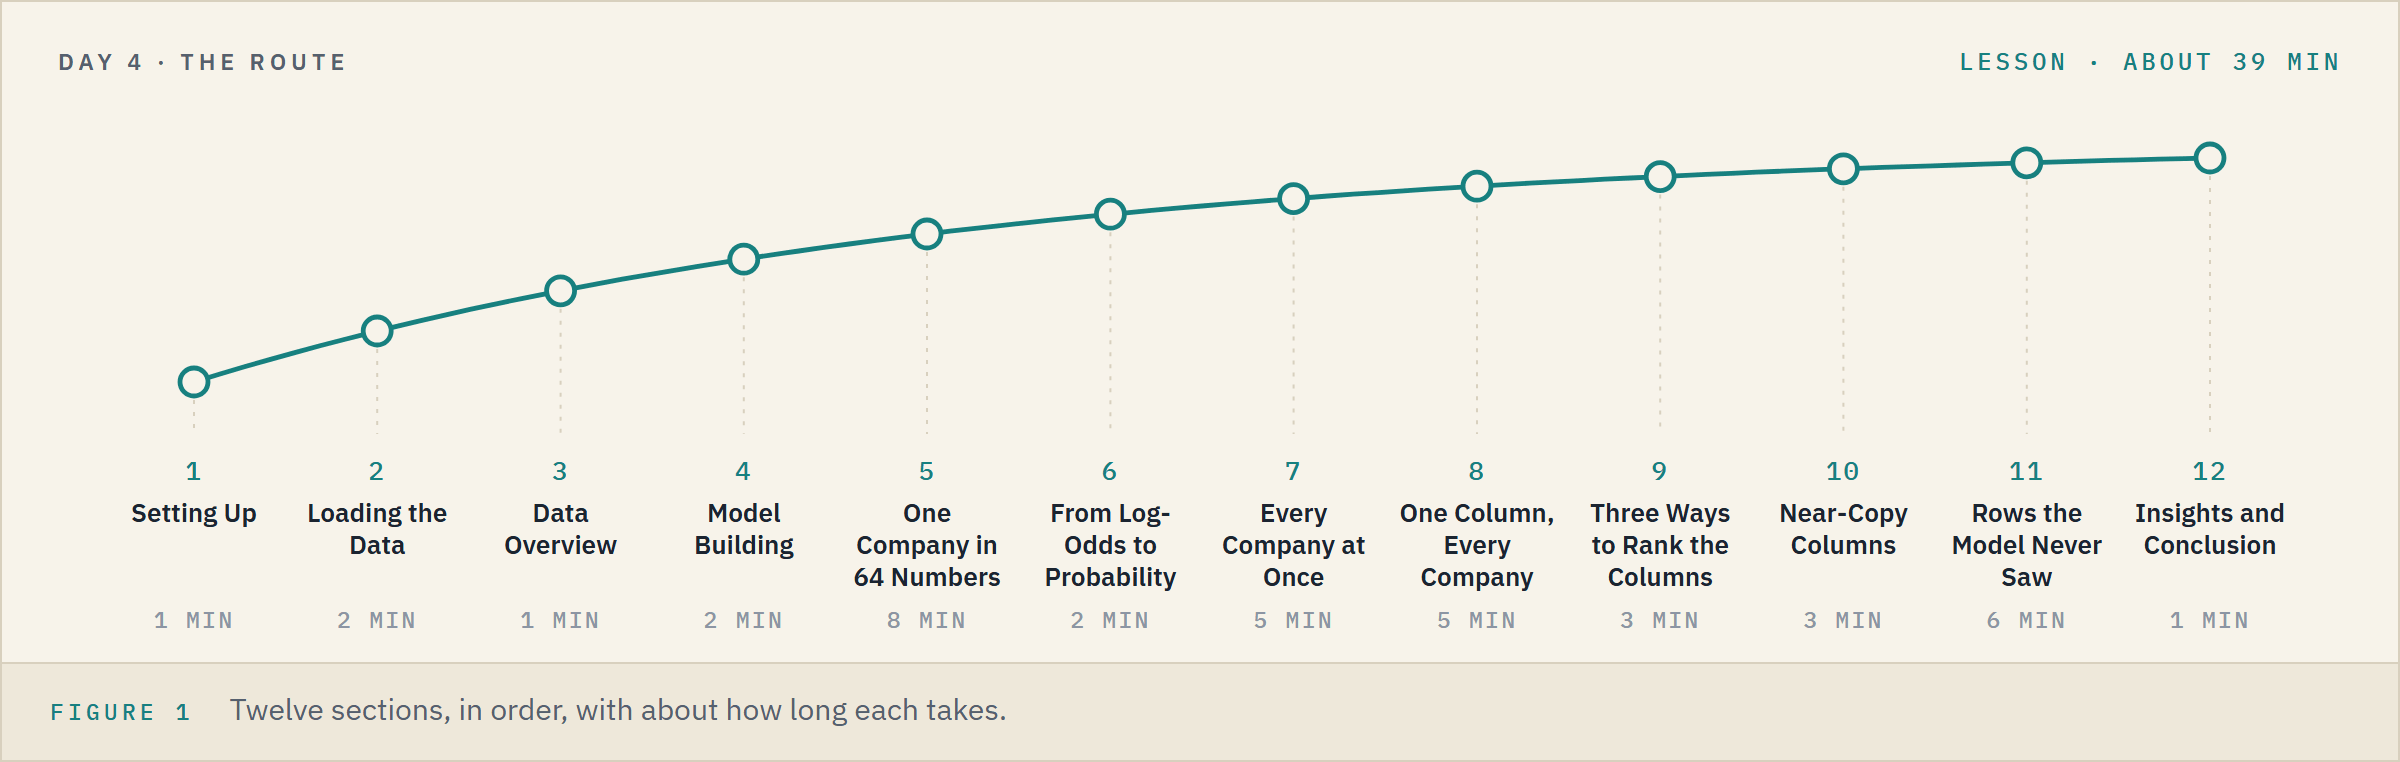

**Time.** About 39 minutes for the lesson, then about 12 for the four exercises.

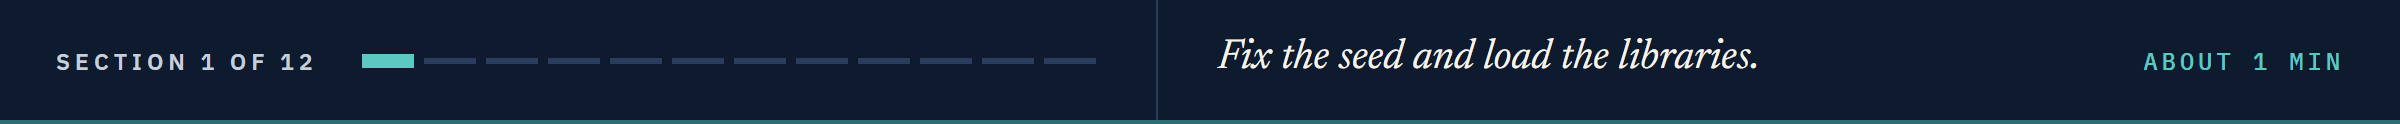

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a dropdown
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split and fold the rows, score by folds, and shuffle columns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.inspection import permutation_importance

# the two boosters, and SHAP to split their outputs
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
import shap

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

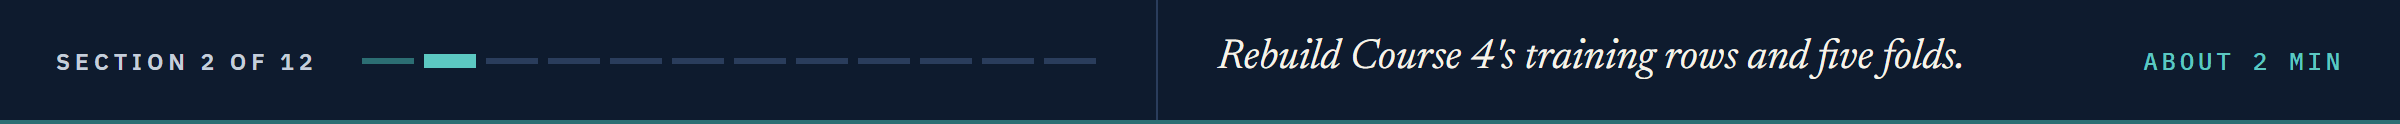

# Loading the Data

## Reading the File

In [3]:
# the 5,910 statements: 64 features named Attr1 to Attr64, and the outcome in class
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]
print(len(bankrupt), "statements,", len(FEATURES), "features")

5910 statements, 64 features


## Rebuilding Course 4's Rows

In [4]:
# Course 4's capstone: the exact copies out, then one stratified 80/20 split with the course seed
unique = bankrupt.drop_duplicates()
X, y = unique[FEATURES], unique[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Training:", len(X_train), "rows,", y_train.sum(), "bankrupt.  Test:", len(X_test), "rows,", y_test.sum(), "bankrupt")

Training: 4680 rows, 326 bankrupt.  Test: 1170 rows, 82 bankrupt


In [5]:
# five stratified folds of the training rows, shuffled with the course seed (Day 11's)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

The same 4,680 training companies and five folds as Days 11 to 13.

The 1,170 test rows are never scored in Course 5.

**The same companies as all week; the test rows stay closed.**

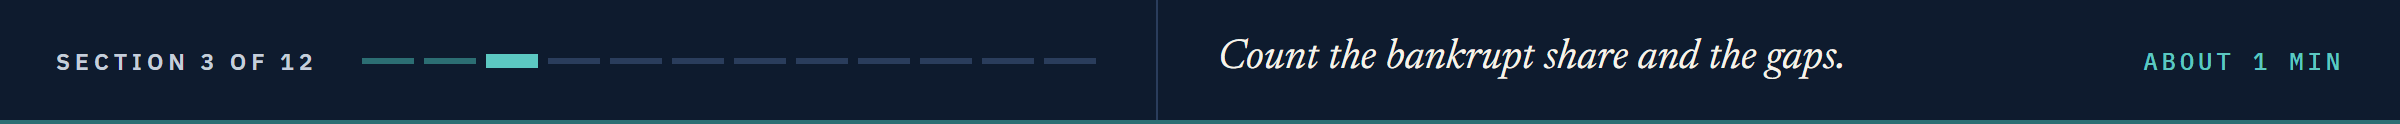

# Data Overview

## The Rare Class and the Gaps

In [6]:
# the bankrupt share, the columns with a gap, and the companies with at least one
print("Bankrupt:", round(y_train.mean() * 100, 2), "percent")
print("Columns with a gap:", X_train.isna().any().sum(), " Companies with at least one:", X_train.isna().any(axis=1).sum())

Bankrupt: 6.97 percent
Columns with a gap: 48  Companies with at least one: 2248


Course 4's capstone and Day 12 explored these columns and their gaps in full.

LightGBM sends a gap down whichever side of a split it learned for gaps (Day 11), so no imputer today.

**The rows go in as they are.**

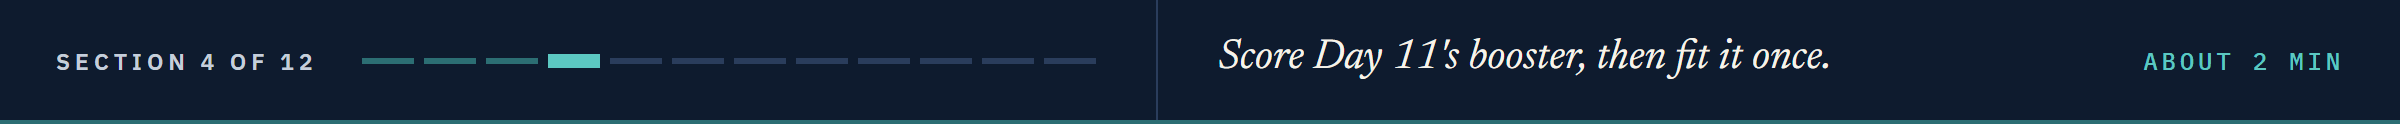

# Model Building

## Day 11's Model, Scored by Folds

In [7]:
# Day 11's booster at its defaults (100 trees), scored by average precision on each fold
model = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)
scores = cross_validate(model, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)
print("Folds:", scores["test_score"].round(4), " Mean:", round(scores["test_score"].mean(), 4))

Folds: [0.7077 0.7988 0.7434 0.8013 0.8405]  Mean: 0.7783


The fold scores Day 11 handed on: the honest score, each fold scored by a model that never saw it.

## The Model the Desk Keeps

In [8]:
# the same booster fitted on all 4,680 companies: the model we describe today
model.fit(X_train, y_train)
proba = model.predict_proba(X_train)[:, 1]
print("Average output:", round(proba.mean(), 4), " Bankrupt share:", round(y_train.mean(), 4))

Average output: 0.0697  Bankrupt share: 0.0697


On its own rows the outputs average the bankrupt share.

Day 11's fitted folds scored 1.0 on rows like these: the model has learned these companies closely.

**One fitted model to describe; from here no company is scored, only described.**

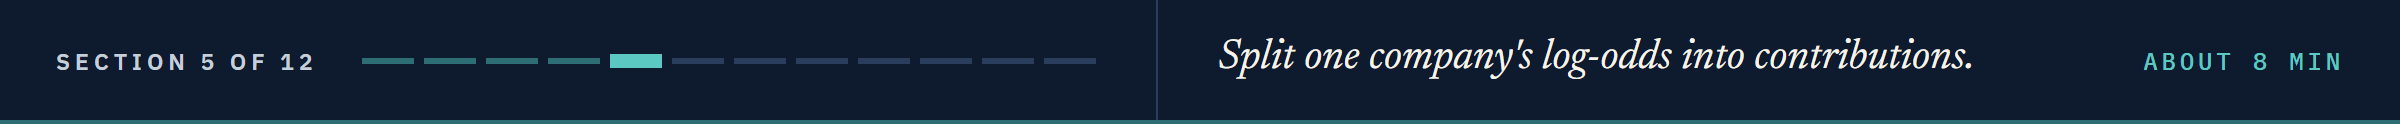

# One Company in 64 Numbers

A **SHAP value** splits one company's model output into one contribution per column.
The output it splits is the model's log-odds (Course 4's Day 6), the number before the logistic curve turns it into a probability.
`model.predict(rows, raw_score=True)` returns LightGBM's log-odds.
Each contribution is the column's **Shapley value**, from game theory: its average step when the columns join in every possible order.
`shap.TreeExplainer(model)` computes those exactly from the trees, and the **base value** is where every company starts, the model's average log-odds over the rows it was fitted on.

**Predict 1**

The model's outputs average 6.97 percent.

Q. The base value is the average of the log-odds. Pass it through the logistic curve: what probability do you get? Write down a number.

## The Base Value

Calling the explainer on rows returns an `Explanation`: `.values` holds one SHAP value per company per column, and `.base_values` the base value, the same for every company.

In [9]:
# the explainer reads the 100 trees; called on the rows, it splits every company's output
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_train)
base = shap_values.base_values[0]
print("SHAP values:", shap_values.values.shape, " Base value:", round(base, 4), "log-odds")

SHAP values: (4680, 64)  Base value: -7.3266 log-odds


In [10]:
# the logistic curve, as in Course 4's Day 6, and the model's own log-odds for every company
def logistic(z):
    return 1 / (1 + np.exp(-z))

log_odds = model.predict(X_train, raw_score=True)
print("Average log-odds:", round(log_odds.mean(), 4))
print("Base value as a probability:", round(logistic(base) * 100, 4), "percent, against an average output of", round(proba.mean() * 100, 2), "percent")

Average log-odds: -7.3266
Base value as a probability: 0.0657 percent, against an average output of 6.97 percent


### Interpretation of the Base Value

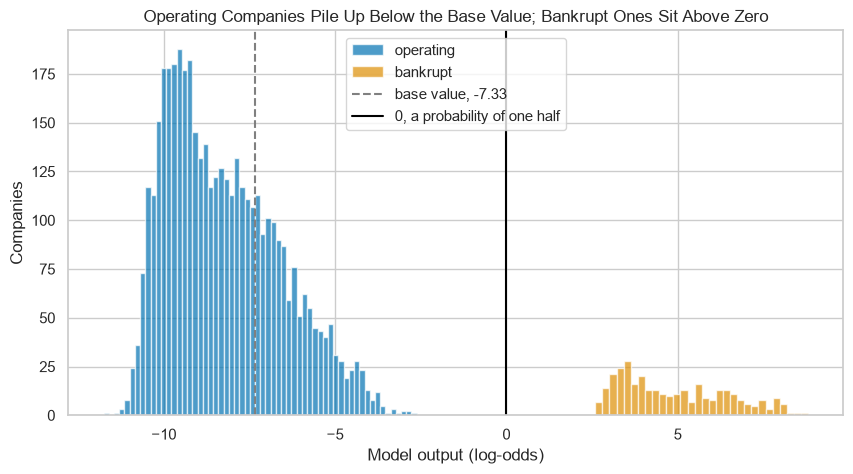

In [11]:
# the 4,680 log-odds by outcome, the base value dashed and 0 (a probability of one half) solid
plt.hist(log_odds[y_train == 0], bins=60, alpha=0.7, label="operating")
plt.hist(log_odds[y_train == 1], bins=30, alpha=0.7, label="bankrupt")
plt.axvline(base, color="gray", linestyle="--", label=f"base value, {base:.2f}")
plt.axvline(0, color="black", label="0, a probability of one half")
plt.xlabel("Model output (log-odds)")
plt.ylabel("Companies")
plt.title("Operating Companies Pile Up Below the Base Value; Bankrupt Ones Sit Above Zero")
plt.legend(loc="upper center")
plt.show()

In [12]:
# where the companies sit against the base value
print("Below the base value:", (log_odds < base).sum(), " Median log-odds:", round(np.median(log_odds), 4))
print("Average log-odds: operating", round(log_odds[y_train == 0].mean(), 3), " bankrupt", round(log_odds[y_train == 1].mean(), 3))

Below the base value: 3105  Median log-odds: -8.3174
Average log-odds: operating -8.242  bankrupt 4.902


3,105 companies, two thirds, sit below the base value: the many operating companies near -8.2 pull the average down, the 326 bankrupt ones near 4.9 pull it up.

The logistic curve is flat at both ends, so the average log-odds lands where almost no probability is, far below the average probability.

## One Bankrupt Company

`np.flatnonzero(condition)` returns the positions where a condition holds.

In [13]:
# the first bankrupt company in the training rows, by position, and its 64 SHAP values beside its ratios
company = np.flatnonzero(y_train == 1)[0]
row = pd.DataFrame({"value": X_train.iloc[company], "SHAP value": shap_values.values[company]})
print("Position:", company, " Log-odds:", round(log_odds[company], 4), " Its SHAP values sum to:", round(row["SHAP value"].sum(), 4))

Position: 13  Log-odds: 3.3282  Its SHAP values sum to: 10.6548


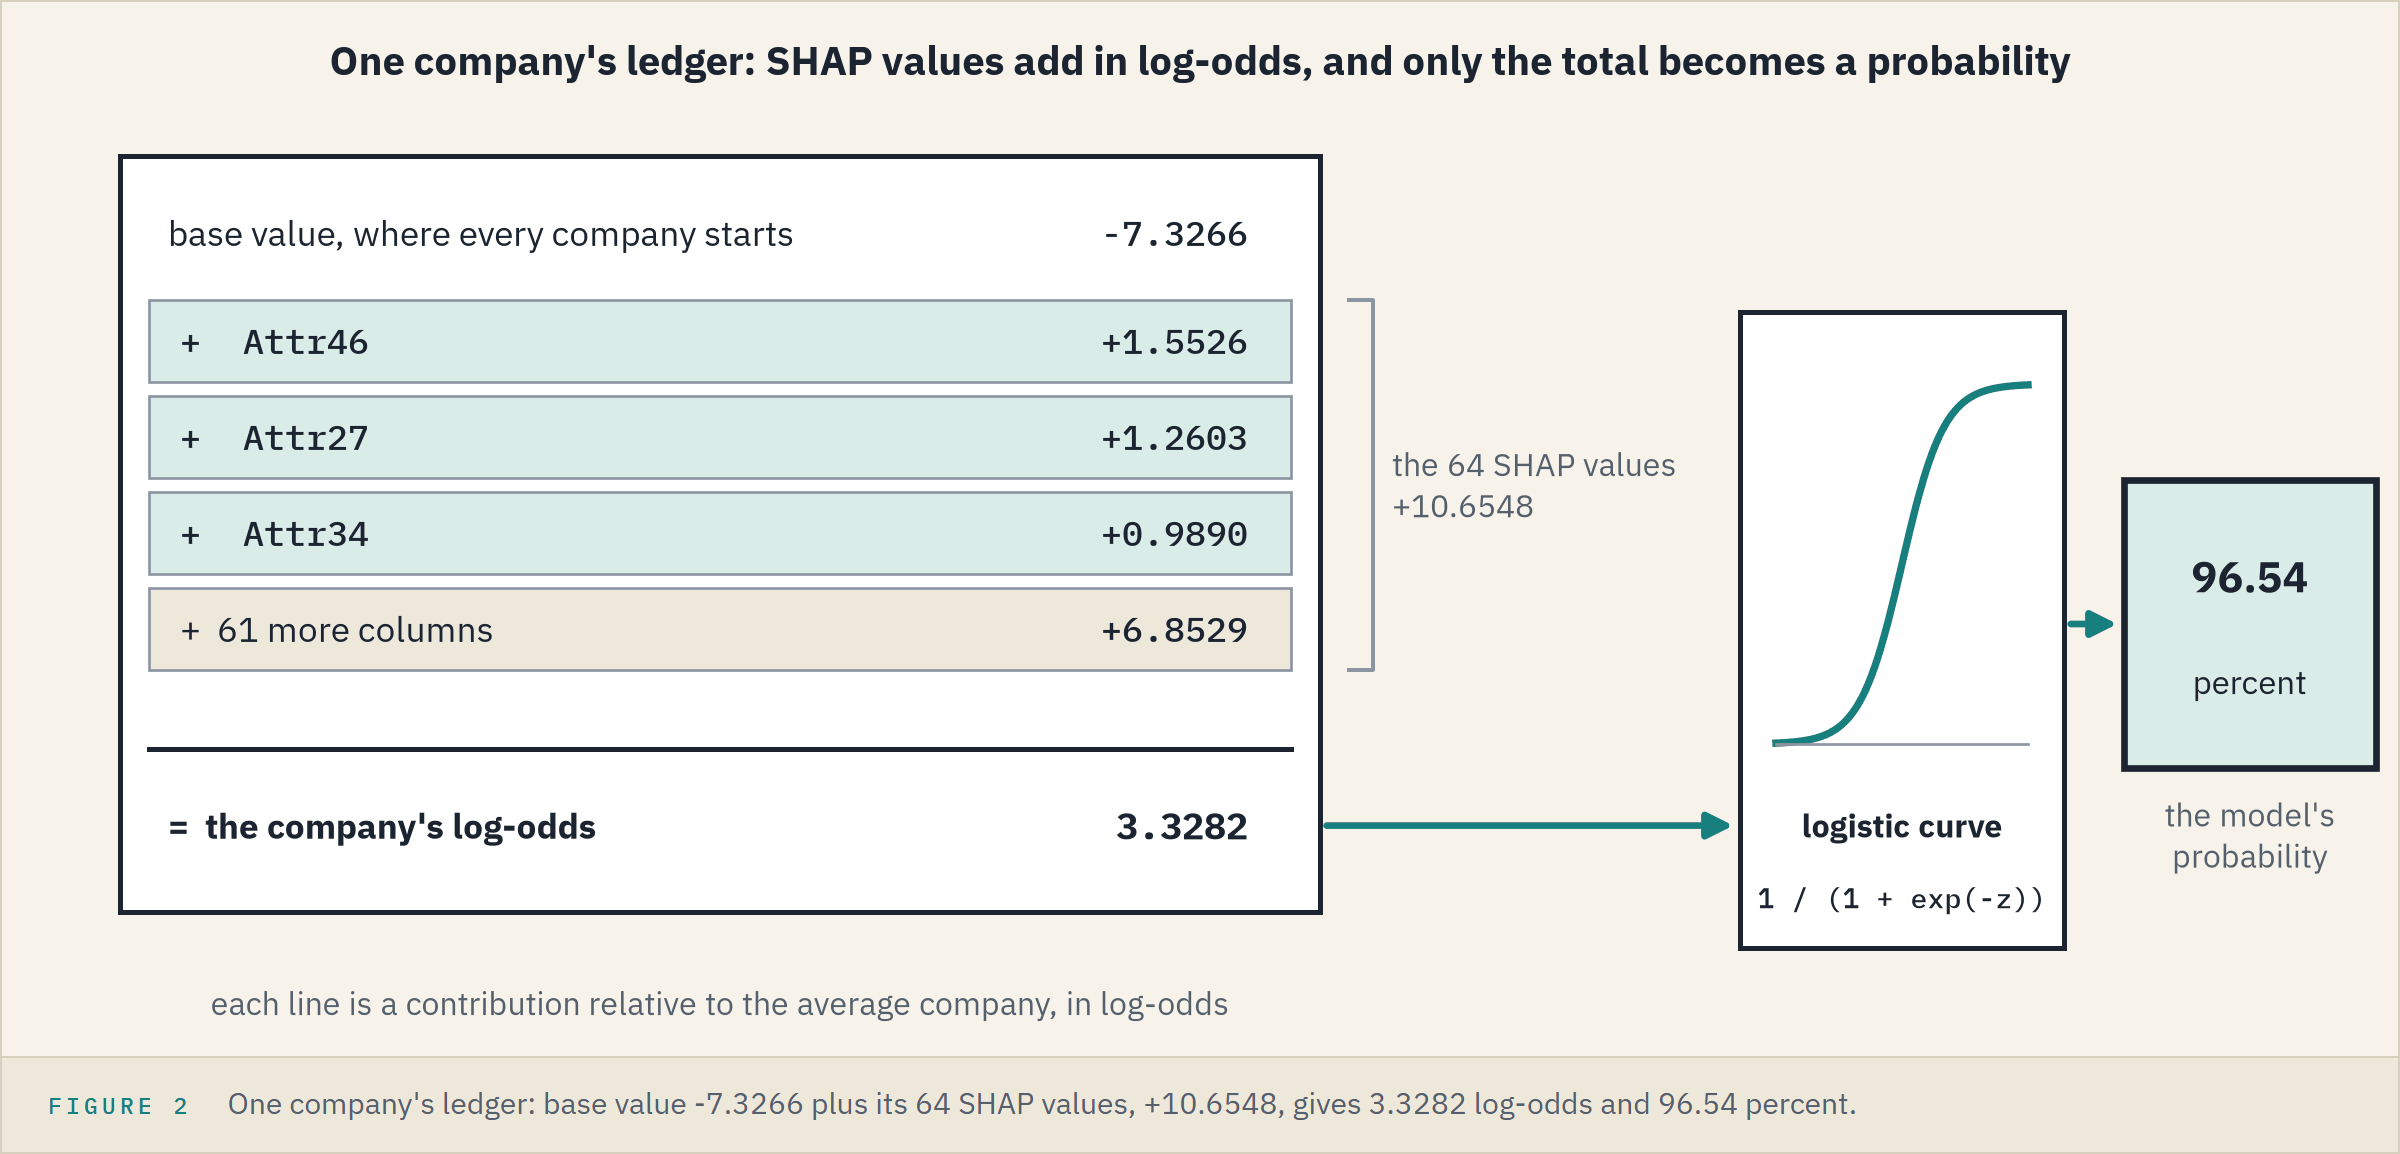

In [14]:
# its eight largest contributions by size, largest first
row.loc[row["SHAP value"].abs().sort_values(ascending=False).index[:8]]

,value,SHAP value
Attr46,0.0420,1.5526
Attr27,-1.7329,1.2603
Attr34,0.5655,0.9890
Attr39,-0.0902,0.9603
Attr38,-1.0383,0.9485
Attr35,-0.0926,0.7060
Attr21,1.0047,0.6845
Attr25,-1.5305,0.4561


In [15]:
# how many of its 64 contributions push up, push down, or are exactly zero
print("Up:", (row["SHAP value"] > 0).sum(), " Down:", (row["SHAP value"] < 0).sum(), " Zero:", list(row.index[row["SHAP value"] == 0]))

Up: 45  Down: 17  Zero: ['Attr14', 'Attr18']


`Attr46`, `Attr27` and `Attr34` add the most to this company's log-odds, each relative to the average company.

45 contributions push up and 17 down; `Attr14` and `Attr18` are exactly zero, because no tree splits on them.

## Every Row Adds Up

In [16]:
# the base value plus each company's 64 SHAP values, against the model's own log-odds, for all 4,680
rebuilt = base + shap_values.values.sum(axis=1)
print("Largest gap over 4,680 companies:", f"{np.abs(rebuilt - log_odds).max():.1e}", "log-odds")

Largest gap over 4,680 companies: 1.6e-13 log-odds


The base value plus a company's SHAP values gives its log-odds to the 13th decimal place, for every company: **additivity**.

## A Waterfall for One Company

`shap_values[company]` picks one company's row of the `Explanation`, its base value and its 64 SHAP values together.

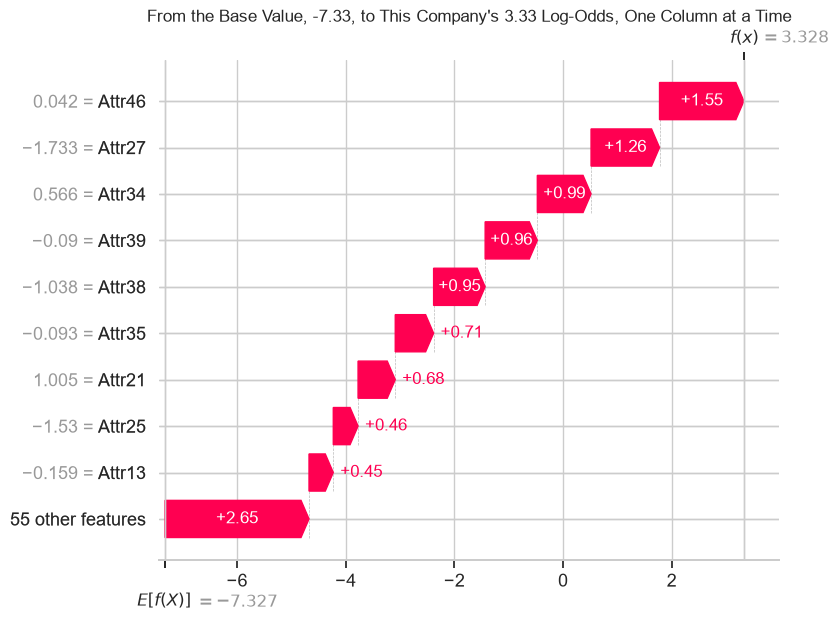

In [17]:
# the company's waterfall: from the base value, its nine largest contributions, the other 55 in one bar
shap.plots.waterfall(shap_values[company], max_display=10, show=False)
plt.title("From the Base Value, -7.33, to This Company's 3.33 Log-Odds, One Column at a Time")
plt.show()

Read from the bottom, E[f(X)], the base value, up to the top, f(x), the company's log-odds; the axis is in log-odds.

Every bar here pushes up and is labelled with its SHAP value; a blue bar would push down.

**Every company's number is a sum we can show line by line, but the sum is in log-odds, and the committee reads probabilities.**

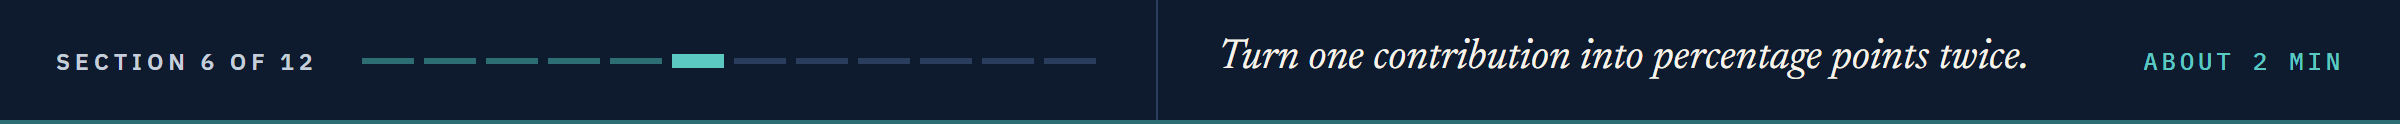

# From Log-Odds to Probability

**Predict 2**

`Attr46` adds 1.5526 log-odds to this company.

Q. In percentage points of probability, what is that step worth counted first, starting from the base value, and counted last, ending at the company's log-odds? Write down two numbers.

## The Same Contribution, Two Places

In [18]:
# Attr46's step counted from the base value, then as the last step into the company's log-odds
step = row.loc["Attr46", "SHAP value"]
first = (logistic(base + step) - logistic(base)) * 100
last = (logistic(log_odds[company]) - logistic(log_odds[company] - step)) * 100
print("From the base value:", round(first, 4), "points.  As the last step:", round(last, 4), "points.  Ratio:", round(last / first))

From the base value: 0.244 points.  As the last step: 11.0222 points.  Ratio: 45


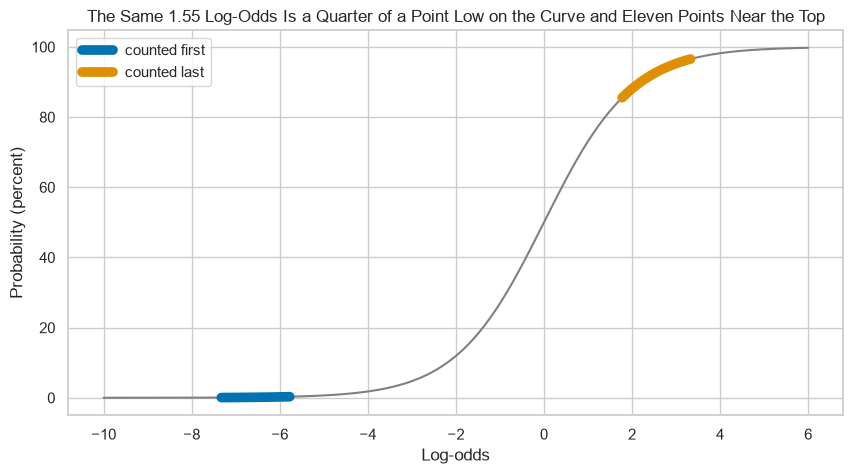

In [19]:
# the logistic curve with the same step drawn thick in both places
z = np.linspace(-10, 6, 400)
plt.plot(z, logistic(z) * 100, color="gray")
for start, colour, label in [(base, "C0", "counted first"), (log_odds[company] - step, "C1", "counted last")]:
    segment = np.linspace(start, start + step, 50)
    plt.plot(segment, logistic(segment) * 100, color=colour, linewidth=7, label=label)
plt.xlabel("Log-odds")
plt.ylabel("Probability (percent)")
plt.title("The Same 1.55 Log-Odds Is a Quarter of a Point Low on the Curve and Eleven Points Near the Top")
plt.legend(loc="upper left")
plt.show()

Equal steps along the log-odds axis buy unequal steps in probability: almost nothing where the curve is flat, a lot where it is steep.

So a SHAP value has no fixed size in percentage points; it depends on everything added before it.

**Contributions are stated in log-odds; only a company's total is turned into a probability.**

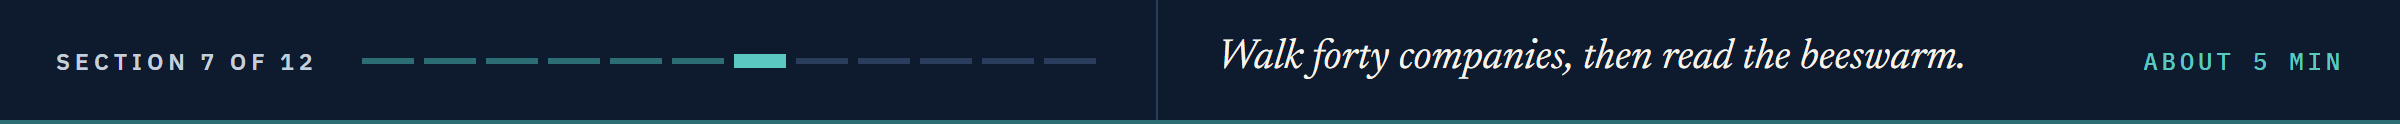

# Every Company at Once

## Mean Absolute SHAP Value

A column's **mean absolute SHAP value** is the average size of its contributions over all the companies: how far the model leans on it, in log-odds.

In [20]:
# each column's mean absolute SHAP value, largest first, and the top three's share of the total
mean_abs = pd.Series(np.abs(shap_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print(mean_abs.head(3).round(4).to_dict())
print("Top three's share of the total:", round(mean_abs.head(3).sum() / mean_abs.sum() * 100, 1), "percent")

{'Attr27': 0.8813, 'Attr21': 0.7035, 'Attr34': 0.6126}
Top three's share of the total: 32.0 percent


## Forty Walks From the Base Value

A **decision-path chart** draws each company as a walk: it starts at the base value and adds one contribution at a time, the 52 smallest columns as one step, then the top 12, the largest last.
`.cumsum(axis=1)` (Day 2's) gives the running sums along each row, and `ax.twiny()`, Day 1's `ax.twinx()` turned on its side, adds a second x axis along the top, here marked in probabilities.

In [21]:
# each company's steps: the 52 smallest columns in one, then the top 12 from the 12th to the 1st
order = list(mean_abs.index[::-1])
steps = pd.DataFrame(shap_values.values, columns=FEATURES)[order]
steps = pd.concat([steps.iloc[:, :52].sum(axis=1).rename("52 other columns"), steps.iloc[:, 52:]], axis=1)
walks = base + steps.cumsum(axis=1)

# 20 bankrupt and 20 operating companies, drawn without replacement (Course 4's Day 12 draw)
rng = np.random.default_rng(SEED)
picked = np.concatenate([rng.choice(np.flatnonzero(y_train == 1), 20, replace=False),
                         rng.choice(np.flatnonzero(y_train == 0), 20, replace=False)])

# probabilities to mark along the top, each placed at its log-odds, ln(p / (1 - p))
chances = np.array([0.0001, 0.001, 0.01, 0.1, 0.5, 0.9, 0.99, 0.999])

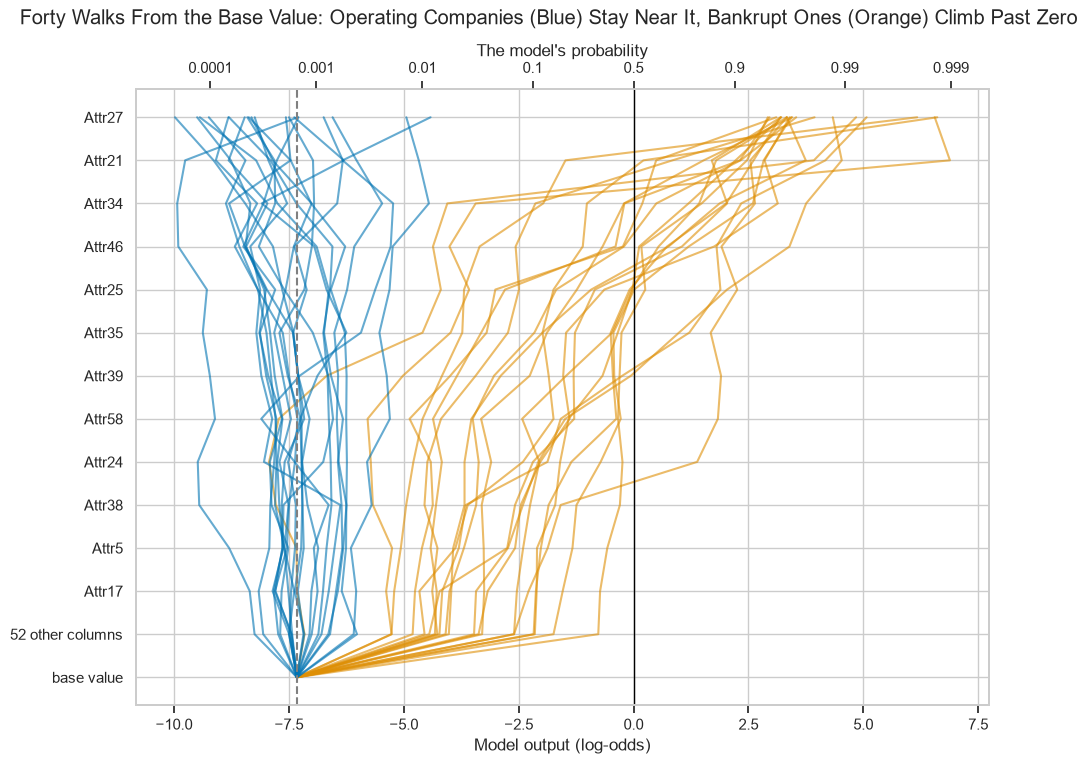

In [22]:
# the showpiece: forty walks from the base value, bankrupt companies in orange, operating in blue
fig, ax = plt.subplots(figsize=(11, 8))
levels = range(len(steps.columns) + 1)
for i in picked:
    ax.plot([base] + list(walks.iloc[i]), levels, color="C1" if y_train.iloc[i] == 1 else "C0", alpha=0.6, linewidth=1.5)
ax.axvline(base, color="gray", linestyle="--")
ax.axvline(0, color="black", linewidth=1)
ax.set(yticks=list(levels), yticklabels=["base value"] + list(steps.columns), xlabel="Model output (log-odds)")
# a second x axis along the top over the same range (ax.get_xlim() reads the bottom axis's range)
top = ax.twiny()
top.set(xlim=ax.get_xlim(), xticks=np.log(chances / (1 - chances)), xticklabels=chances, xlabel="The model's probability")
top.grid(False)
fig.suptitle("Forty Walks From the Base Value: Operating Companies (Blue) Stay Near It, Bankrupt Ones (Orange) Climb Past Zero")
plt.show()

In [23]:
# for the 20 bankrupt walks: the climb from the base value, and the part made in the last three steps
bankrupt_walks = walks.iloc[picked[:20]]
climb = bankrupt_walks.iloc[:, -1] - base
last_three = bankrupt_walks.iloc[:, -1] - bankrupt_walks.iloc[:, -4]
print("Median climb:", round(climb.median(), 2), "log-odds.  Median share in the last three steps:", round((last_three / climb).median() * 100, 1), "percent")

Median climb: 10.74 log-odds.  Median share in the last three steps: 28.1 percent


Every walk starts at the base value; the operating walks wander and end near it, most below 0.01 on the top scale.

The bankrupt walks climb a median 10.74 log-odds and all cross zero.

For 19 of the 20 bankrupt walks the 52 smallest columns together already add two log-odds or more.

The last three steps, `Attr34`, `Attr21` and `Attr27`, add a median 28.1 percent of the climb.

## The Beeswarm

A **beeswarm** puts one dot per company in each column's row, at its SHAP value, coloured by the column's own value: red high, blue low, grey for a gap.
`shap.summary_plot(..., rng=SEED)` draws it with a seeded stacking of the dots.

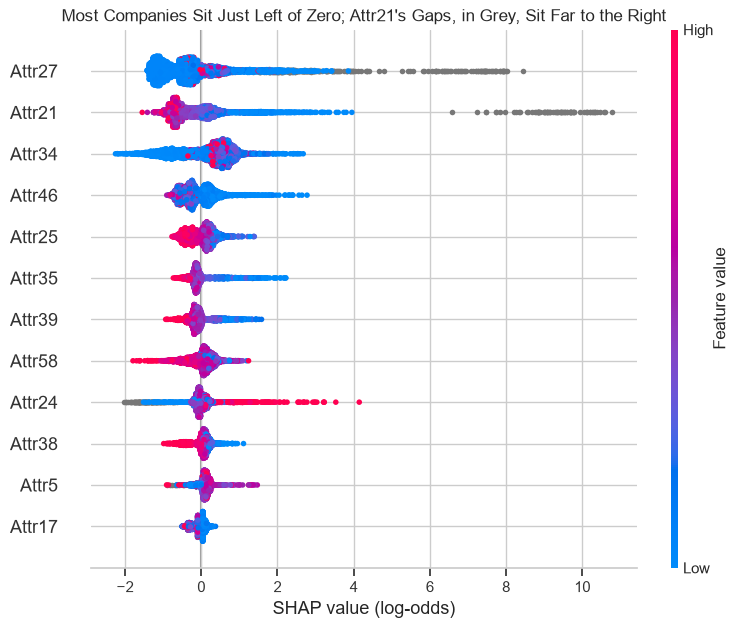

In [24]:
# every company's SHAP value in the twelve columns the model leans on most
shap.summary_plot(shap_values, max_display=12, rng=SEED, show=False)
plt.xlabel("SHAP value (log-odds)")
plt.title("Most Companies Sit Just Left of Zero; Attr21's Gaps, in Grey, Sit Far to the Right")
plt.show()

One row per column, the most leaned-on at the top; most dots sit just left of zero, the many operating companies nudged down a little.

`Attr21`'s grey dots, its gaps, sit apart on the far right, from about 6.5 to 11 log-odds.

`Attr34` reads cleanly: blue dots, its low values, sit left of zero, and red dots, its high values, to the right.

## Bankrupt and Operating Companies Apart

A **cohort** is a group of rows; `shap.plots.bar` given a dictionary of cohorts draws their mean absolute SHAP values side by side.

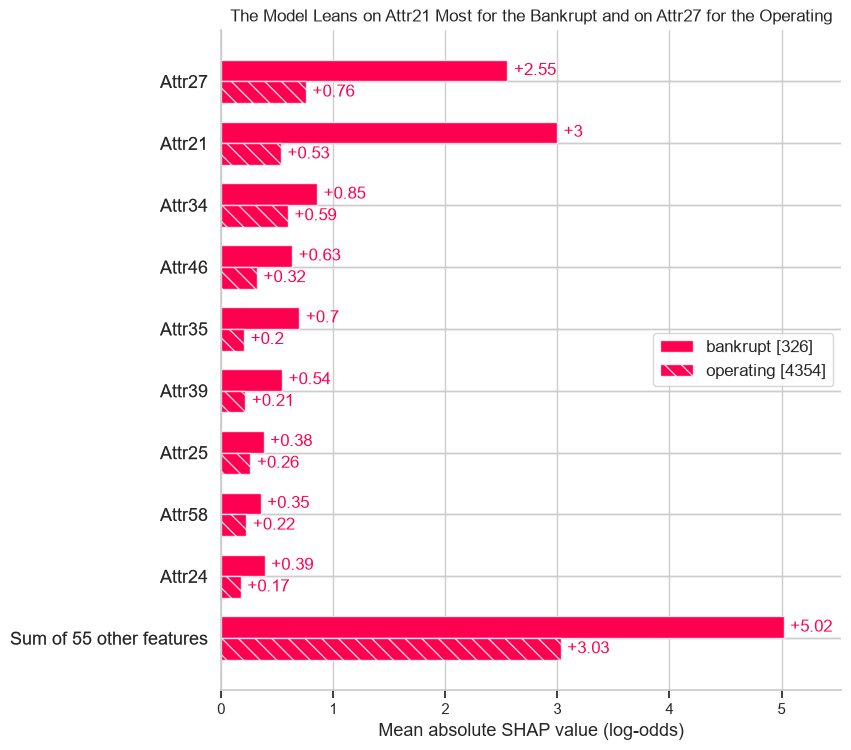

In [25]:
# mean absolute SHAP value of each column, for the bankrupt and the operating companies separately
cohorts = {"bankrupt": shap_values[(y_train == 1).to_numpy()], "operating": shap_values[(y_train == 0).to_numpy()]}
shap.plots.bar(cohorts, max_display=10, show=False)
plt.xlabel("Mean absolute SHAP value (log-odds)")
plt.title("The Model Leans on Attr21 Most for the Bankrupt and on Attr27 for the Operating")
plt.show()

For the bankrupt companies `Attr21` is the largest, 3 log-odds on average; for the operating ones `Attr27`, 0.76.

Every bankrupt bar is longer than its operating twin: their outputs sit far from the base value.

**The model leans on different columns for different companies; one column at a time shows how.**

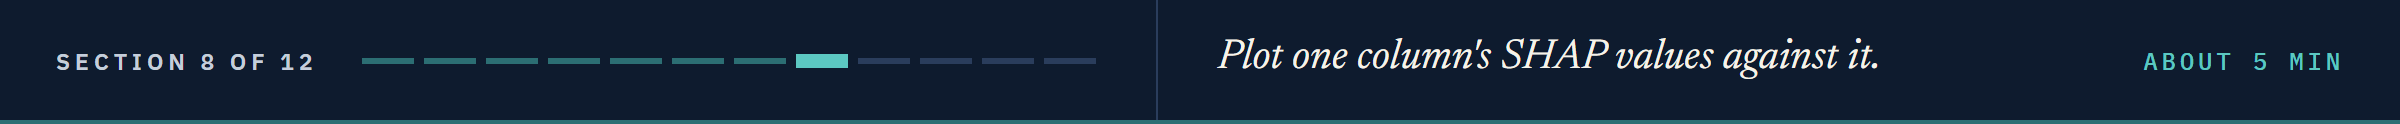

# One Column, Every Company

**Predict 3**

`Attr27` is operating profit over financial expenses: below 0 the company loses money before interest, above 1 its operating profit covers its financial expenses.

Q. Sketch `Attr27`'s SHAP value (up) against `Attr27` (across), from deeply negative to very large.

## A Dependence Plot of Attr27

A **dependence plot** draws one column's SHAP values against the column's values, one dot per company.
A company with a gap has no value to place, so the gaps get a strip of their own on the left, a **gap strip**.
`shap_values[:, "Attr27"]` picks one column of an `Explanation` by name, and `ax.set(xscale="symlog")` (Course 4's Day 10) keeps a ratio's long tails on the page.

In [26]:
# one column's SHAP values against its values: gaps in a strip on the left, the rest on a symlog axis
def draw_dependence(column):
    contributions = pd.Series(shap_values[:, column].values, index=X_train.index)
    fig, (strip, ax) = plt.subplots(1, 2, figsize=(11, 5), sharey=True, width_ratios=[1, 7])
    for outcome, colour, name in [(0, "C0", "operating"), (1, "C1", "bankrupt")]:
        values = X_train.loc[y_train == outcome, column]
        strip.scatter([0] * values.isna().sum(), contributions[values.index[values.isna()]], color=colour, s=10, alpha=0.5)
        ax.scatter(values.dropna(), contributions[values.dropna().index], color=colour, s=10, alpha=0.5, label=name)
    strip.set(xticks=[0], xticklabels=["gap"], ylabel=f"SHAP value of {column} (log-odds)")
    ax.set(xscale="symlog", xlabel=f"{column} (symlog scale)", title=f"The Model's Contributions From {column}, Against {column}")
    ax.axhline(0, color="gray")
    ax.legend(loc="upper right")
    plt.show()

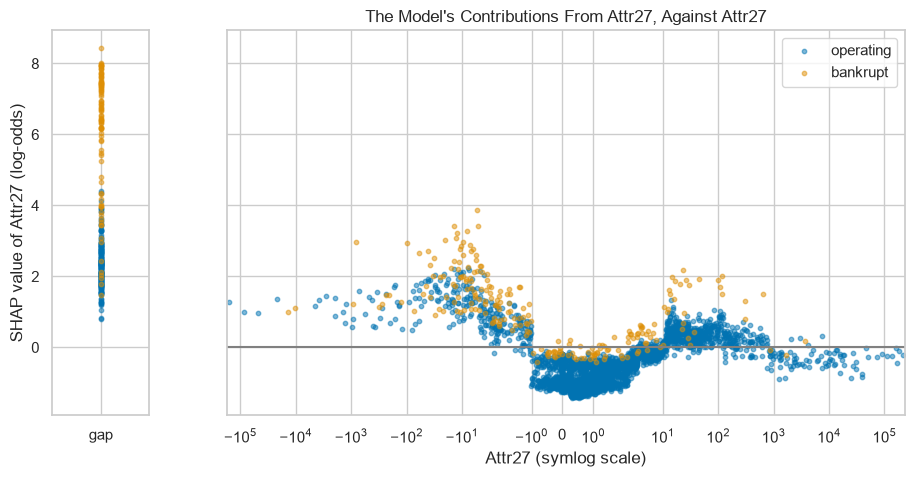

In [27]:
# Attr27, the column the model leans on most
draw_dependence("Attr27")

In [28]:
# Attr27 in four bands: companies, the bankrupt share in percent, and Attr27's average SHAP value
cover = X_train["Attr27"]
band = np.where(cover.isna(), "gap", np.where(cover <= 0, "0 or below", np.where(cover <= 1, "above 0, up to 1", "above 1")))
bands = pd.DataFrame({"band": band, "bankrupt": y_train.to_numpy() * 100, "SHAP": shap_values[:, "Attr27"].values})
bands.groupby("band").agg(companies=("bankrupt", "size"), bankrupt_percent=("bankrupt", "mean"), average_SHAP=("SHAP", "mean"))

,companies,bankrupt_percent,average_SHAP
band,,,
0 or below,974,14.6817,0.1277
"above 0, up to 1",1225,1.1429,-1.0321
above 1,2164,3.4658,-0.2202
gap,317,29.6530,3.4480


The gap strip sits highest: 317 companies with no `Attr27`, 29.65 percent of them bankrupt, pushed up by 3.45 log-odds on average.

Below -1 almost all the contributions sit above zero, around +1; between 0 and 1 they are the lowest of all, -1.03 on average.

Above 1 they climb back to around zero: not a straight line, and not even one direction.

### Interpretation of the Dependence Plot

The plot shows how this model uses `Attr27` on these companies, an association in this file.

It is not the effect of raising a company's cover: the model never saw a company change, only companies that differ.

### Your Turn: Any of the Top Ten

In [29]:
# your turn: the dependence plot of any of the ten columns the model leans on most
interact(draw_dependence, column=list(mean_abs.index[:10]));

interactive(children=(Dropdown(description='column', options=('Attr27', 'Attr21', 'Attr34', 'Attr46', 'Attr25'…

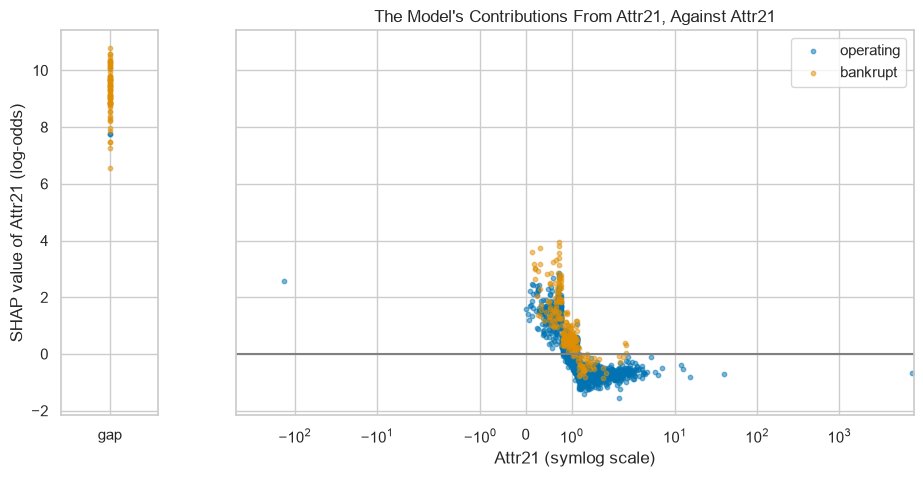

In [30]:
# Attr21 from the dropdown, drawn as a still picture (dropdowns do not run on GitHub)
draw_dependence("Attr21")

In [31]:
# Attr21's gaps against its values: companies, bankrupt among them, and the average SHAP value of Attr21
growth_gap = X_train["Attr21"].isna()
growth = pd.Series(shap_values[:, "Attr21"].values, index=X_train.index)
print("Gaps:", growth_gap.sum(), " Bankrupt among them:", y_train[growth_gap].sum(), " Average SHAP value:", round(growth[growth_gap].mean(), 4), " Lowest:", round(growth[growth_gap].min(), 4))
print("With a value: average SHAP value", round(growth[~growth_gap].mean(), 4))

Gaps: 79  Bankrupt among them: 77  Average SHAP value: 9.2526  Lowest: 6.5679
With a value: average SHAP value -0.1773


79 companies have no `Attr21`, 77 of them bankrupt, and every one gets at least 6.57 log-odds from the gap alone, 9.25 on average.

With a value, `Attr21` contributes -0.18 on average: up where sales shrank, below 1, and down, about -0.5, at 1 or above.

The page does not say why a value is missing; the model has learned that a gap here goes with bankruptcy in this file.

**A gap can carry the largest contribution in the model; a dependence plot shows the model's use of a column, an association in this file.**

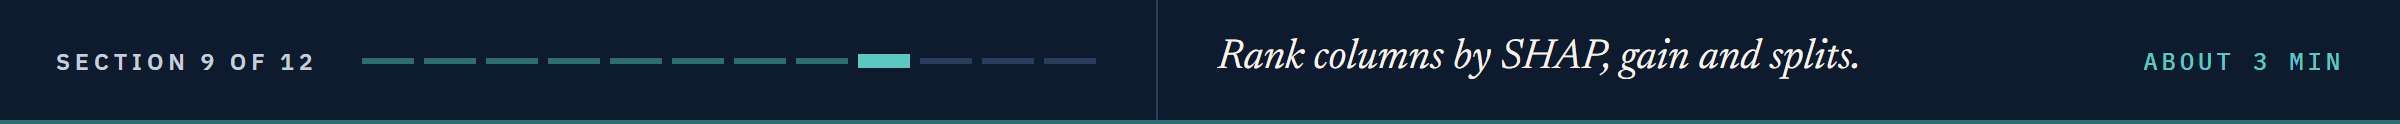

# Three Ways to Rank the Columns

## Mean Absolute SHAP Value, Gain and Split Counts

Day 9 ranked LightGBM's columns by split count and by **gain**, the improvement in the training loss summed over a column's splits, `model.booster_.feature_importance("gain")`.

In [32]:
# each column's mean absolute SHAP value, gain and split count, then its rank on each (1 is the most)
measures = pd.DataFrame({"SHAP": np.abs(shap_values.values).mean(axis=0),
                         "gain": model.booster_.feature_importance("gain"),
                         "splits": model.booster_.feature_importance("split")}, index=FEATURES)
ranks = measures.rank(ascending=False, method="min").astype(int).sort_values("SHAP")
ranks.head(12).T

,Attr27,Attr21,Attr34,Attr46,Attr25,Attr35,Attr39,Attr58,Attr24,Attr38,Attr5,Attr17
SHAP,1,2,3,4,5,6,7,8,9,10,11,12
gain,1,2,3,4,11,6,10,8,7,23,9,51
splits,2,1,3,6,10,8,18,5,4,24,12,56


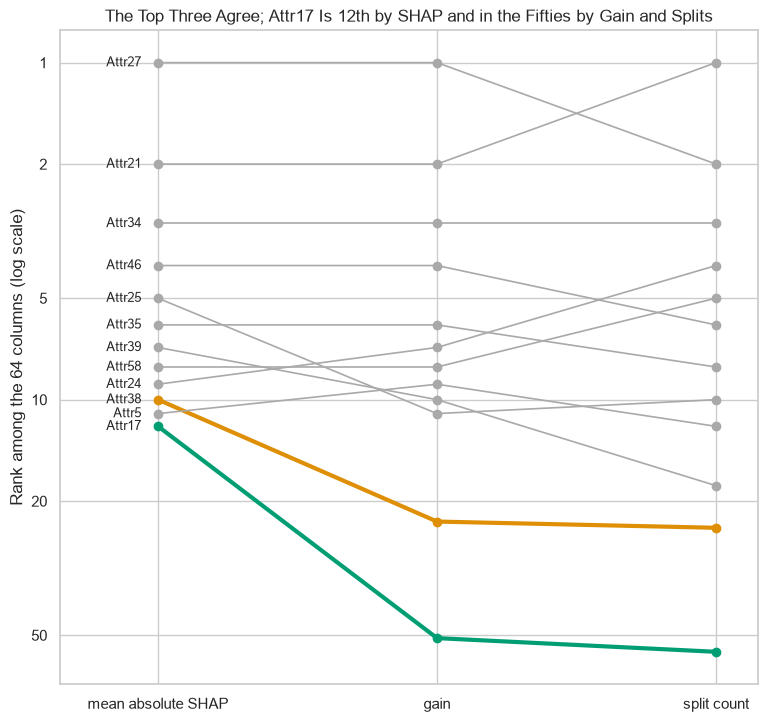

In [33]:
# a slopegraph of the top 12 by SHAP, ranks on a log axis so the top ones spread out, two columns highlighted
fig, ax = plt.subplots(figsize=(9, 8.5))
for name in ranks.index[:12]:
    colour = {"Attr38": "C1", "Attr17": "C2"}.get(name, "darkgray")
    ax.plot([0, 1, 2], ranks.loc[name], marker="o", color=colour, linewidth=3 if colour != "darkgray" else 1.2)
    ax.text(-0.06, ranks.loc[name, "SHAP"], name, ha="right", va="center", fontsize=9)
ax.set(xticks=[0, 1, 2], xticklabels=["mean absolute SHAP", "gain", "split count"], xlim=(-0.35, 2.15), yscale="log")
ax.set(yticks=[1, 2, 5, 10, 20, 50], yticklabels=[1, 2, 5, 10, 20, 50], ylim=(70, 0.8), ylabel="Rank among the 64 columns (log scale)")
ax.minorticks_off()
ax.set_title("The Top Three Agree; Attr17 Is 12th by SHAP and in the Fifties by Gain and Splits")
plt.show()

`Attr27`, `Attr21` and `Attr34` are the top three by SHAP and by gain; split counts put `Attr21` first.

`Attr38` is 10th by SHAP and in the twenties by the other two; `Attr17` 12th by SHAP and in the fifties.

### Interpretation of Attr17's Rank

`trees_to_dataframe()` (Day 9's) lists every node of the 100 trees with its depth and the companies that reach it.

In [34]:
# Attr17's splits in the 100 trees: how deep they sit and how many companies reach each
nodes = model.booster_.trees_to_dataframe()
attr17 = nodes[nodes["split_feature"] == "Attr17"]
print("Splits:", len(attr17), " At depth 2:", (attr17["node_depth"] == 2).sum(), " Companies reaching those:", attr17.loc[attr17["node_depth"] == 2, "count"].min(), "or more")

Splits: 13  At depth 2: 10  Companies reaching those: 2316 or more


10 of `Attr17`'s 13 splits sit just under the root, each reached by 2,316 companies or more, about half the file.

A small step given to half the companies adds up in a mean absolute SHAP value, while each split improved the training loss little.

**Each measure answers its own question: how much a column moves the outputs, how much it improved the fit, how often it was used. Quote the one you mean.**

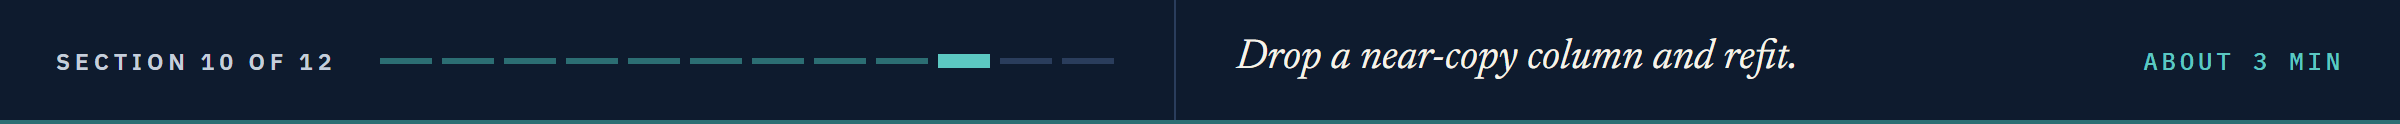

# Near-Copy Columns

## Attr2 and Attr17

In [35]:
# Attr17 is total assets over total liabilities and Attr2 the reverse: is one the reciprocal of the other?
both = X_train[["Attr2", "Attr17"]].dropna()
print("Companies with both:", len(both), " Reciprocal within 1 percent:", np.isclose(both["Attr17"], 1 / both["Attr2"], rtol=0.01).sum())
print("Mean absolute SHAP value: Attr17", round(measures.loc["Attr17", "SHAP"], 4), " Attr2", round(measures.loc["Attr2", "SHAP"], 4))

Companies with both: 4666  Reciprocal within 1 percent: 4665
Mean absolute SHAP value: Attr17 0.1348  Attr2 0.0255


The two columns hold the same fact for almost every company, yet the model leans on `Attr17` about five times as much as on `Attr2`.

The trees happened to split on `Attr17`; SHAP shares a contribution only among the columns the trees use.

**Predict 4**

Q. Refit the model without `Attr17`. What mean absolute SHAP value will `Attr2`, its near-copy, get? Write down a number.

## Refitting Without Attr17

In [36]:
# the same booster fitted without Attr17, and the mean absolute SHAP values of its columns
X_no17 = X_train.drop(columns="Attr17")
model_no17 = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1).fit(X_no17, y_train)
mean_abs_no17 = pd.Series(np.abs(shap.TreeExplainer(model_no17)(X_no17).values).mean(axis=0), index=X_no17.columns)
print("Attr2 without Attr17:", round(mean_abs_no17["Attr2"], 4))

Attr2 without Attr17: 0.0287


In [37]:
# which columns gained the most when Attr17 left, and by how much
change = (mean_abs_no17 - measures["SHAP"].drop("Attr17")).sort_values(ascending=False)
change.head(3)

Attr8    0.0912
Attr39   0.0603
Attr34   0.0577
dtype: float64

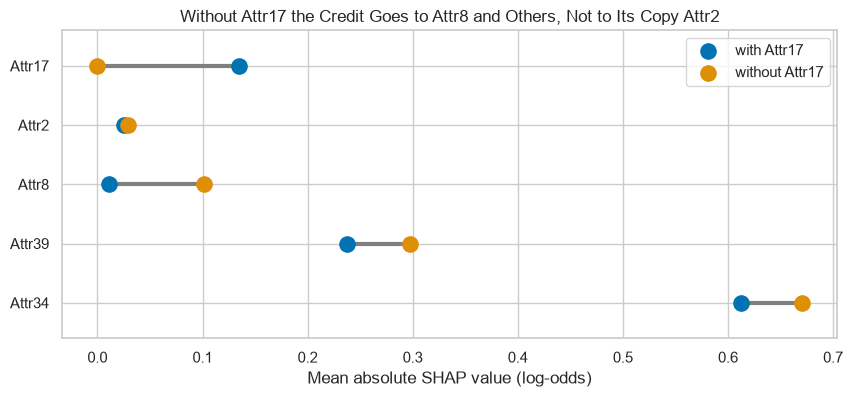

In [38]:
# a dumbbell for five columns: mean absolute SHAP value with Attr17 in the model and without it
shown = ["Attr17", "Attr2", "Attr8", "Attr39", "Attr34"]
with_17 = measures.loc[shown, "SHAP"]
without_17 = mean_abs_no17.reindex(shown, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.hlines(shown, with_17, without_17, color="gray", linewidth=3)
ax.scatter(with_17, shown, s=120, label="with Attr17", zorder=3)
ax.scatter(without_17, shown, s=120, label="without Attr17", zorder=3)
ax.set(xlabel="Mean absolute SHAP value (log-odds)", ylim=(4.6, -0.6))
ax.set_title("Without Attr17 the Credit Goes to Attr8 and Others, Not to Its Copy Attr2")
ax.legend(loc="upper right")
plt.show()

`Attr2` barely moves; `Attr8`, book equity over total liabilities, gains the most.

`Attr8` compares the same two sides of the balance sheet another way, and the trees take it up instead.

**Credit goes to the column the trees happened to use; a small SHAP value does not mean the information is absent.**

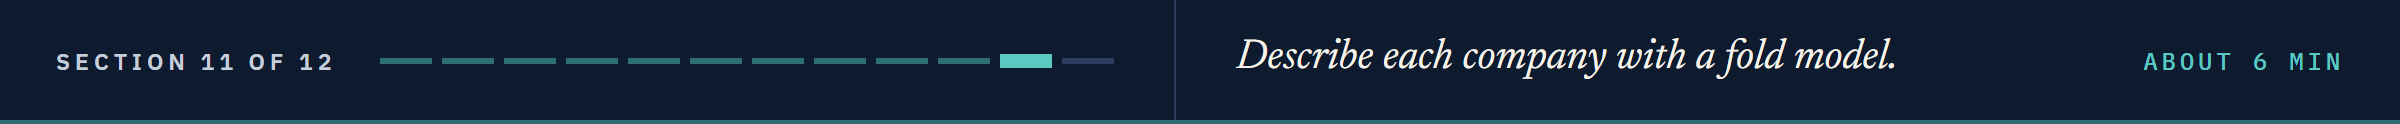

# Rows the Model Never Saw

Day 11's folds give each company a model that never saw it: fit on four folds, explain the fifth.

## Five Fold Models, Each Describing Its Held-Out Companies

In [39]:
# for each fold: fit on the other four, then keep the held-out companies' SHAP values, base values and log-odds
fold_values, fold_base, fold_log_odds = np.zeros(X_train.shape), np.zeros(len(X_train)), np.zeros(len(X_train))
for fit_rows, held_rows in folds.split(X_train, y_train):
    fold_model = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1).fit(X_train.iloc[fit_rows], y_train.iloc[fit_rows])
    explained = shap.TreeExplainer(fold_model)(X_train.iloc[held_rows])
    fold_values[held_rows], fold_base[held_rows] = explained.values, explained.base_values
    fold_log_odds[held_rows] = fold_model.predict(X_train.iloc[held_rows], raw_score=True)

In [40]:
# the sums still hold, and each fold model has its own base value
print("Largest gap:", f"{np.abs(fold_base + fold_values.sum(axis=1) - fold_log_odds).max():.1e}", "log-odds")
print("Base values:", round(fold_base.min(), 4), "to", round(fold_base.max(), 4))

Largest gap: 2.2e-12 log-odds
Base values: -8.0912 to -7.8239


**Predict 5**

The company we followed sat at 3.3282 log-odds, a probability of 96.54 percent, under the model that learned it.

Q. What log-odds does the fold model that never saw it give? Write down a number.

## The Same Company, Unseen

In [41]:
# the company's log-odds from the model that saw it and from the one that did not, and its top three out of fold
print("Fitted on it:", round(log_odds[company], 4), "  Never saw it:", round(fold_log_odds[company], 4), "=", round(logistic(fold_log_odds[company]) * 100, 2), "percent")
print("Out of fold its SHAP values sum to:", round(fold_values[company].sum(), 4), " Largest:", list(pd.Series(np.abs(fold_values[company]), index=FEATURES).nlargest(3).index))

Fitted on it: 3.3282   Never saw it: -4.3623 = 1.26 percent
Out of fold its SHAP values sum to: 3.6251  Largest: ['Attr46', 'Attr27', 'Attr24']


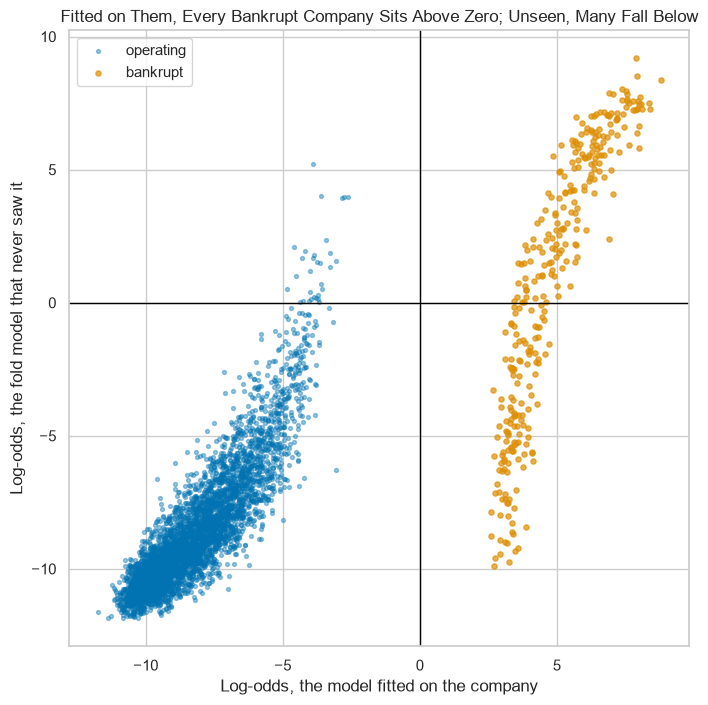

In [42]:
# every company's log-odds, fitted on it against never seen, by outcome; zero marked on both axes
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(log_odds[y_train == 0], fold_log_odds[y_train == 0], s=8, alpha=0.4, label="operating")
ax.scatter(log_odds[y_train == 1], fold_log_odds[y_train == 1], s=14, alpha=0.7, color="C1", label="bankrupt")
ax.axvline(0, color="black", linewidth=1)
ax.axhline(0, color="black", linewidth=1)
ax.set(xlabel="Log-odds, the model fitted on the company", ylabel="Log-odds, the fold model that never saw it")
ax.set_title("Fitted on Them, Every Bankrupt Company Sits Above Zero; Unseen, Many Fall Below")
ax.legend(loc="upper left")
plt.show()

In [43]:
# above zero, a probability over one half, under each description
print("Fitted on them: bankrupt above 0", ((log_odds > 0) & (y_train == 1)).sum(), " operating above 0", ((log_odds > 0) & (y_train == 0)).sum())
print("Never saw them: bankrupt above 0", ((fold_log_odds > 0) & (y_train == 1)).sum(), " operating above 0", ((fold_log_odds > 0) & (y_train == 0)).sum())

Fitted on them: bankrupt above 0 326  operating above 0 0
Never saw them: bankrupt above 0 191  operating above 0 31


Fitted on them, all 326 bankrupt companies sit above zero and no operating company does: the model has memorised the file.

Out of fold, 191 of the 326 stay above zero, and 31 operating companies cross it.

Our company falls from 96.54 percent to 1.26 percent: `Attr46` and `Attr27` still lead its contributions, but the 64 together add 3.63 log-odds in place of 10.65.

## The Ranking Holds

In [44]:
# the top ten columns by mean absolute SHAP value, fitted against out of fold
mean_abs_fold = pd.Series(np.abs(fold_values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("Fitted:     ", list(mean_abs.index[:10]))
print("Out of fold:", list(mean_abs_fold.index[:10]))

Fitted:      ['Attr27', 'Attr21', 'Attr34', 'Attr46', 'Attr25', 'Attr35', 'Attr39', 'Attr58', 'Attr24', 'Attr38']
Out of fold: ['Attr27', 'Attr21', 'Attr34', 'Attr46', 'Attr25', 'Attr35', 'Attr39', 'Attr58', 'Attr24', 'Attr38']


The same ten columns in the same order: company by company the stories move, but what the model leans on across the file holds.

## A Second Booster

`XGBClassifier.predict(rows, output_margin=True)` returns XGBoost's log-odds; XGBoost works in 32-bit floats, about seven significant digits.

In [45]:
# Day 8's XGBoost at its defaults on the same companies, its SHAP values, and how closely they add up
booster = XGBClassifier(random_state=SEED, n_jobs=1).fit(X_train, y_train)
xgb_values = shap.TreeExplainer(booster)(X_train)
gap = np.abs(xgb_values.base_values + xgb_values.values.sum(axis=1) - booster.predict(X_train, output_margin=True)).max()
mean_abs_xgb = pd.Series(np.abs(xgb_values.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print("Stored as:", xgb_values.values.dtype, " Largest gap:", f"{gap:.1e}", "log-odds")
print("Top ten shared with LightGBM:", len(set(mean_abs_xgb.index[:10]) & set(mean_abs.index[:10])))

Stored as: float32  Largest gap: 7.6e-06 log-odds
Top ten shared with LightGBM: 9


The sums hold to about 1e-5, not 1e-13: seven digits on numbers near 10 leave rounding in the sixth decimal place.

Attr17: {'LightGBM, fitted': 0.1348, 'LightGBM, out of fold': 0.0504, 'XGBoost, fitted': 0.0451}


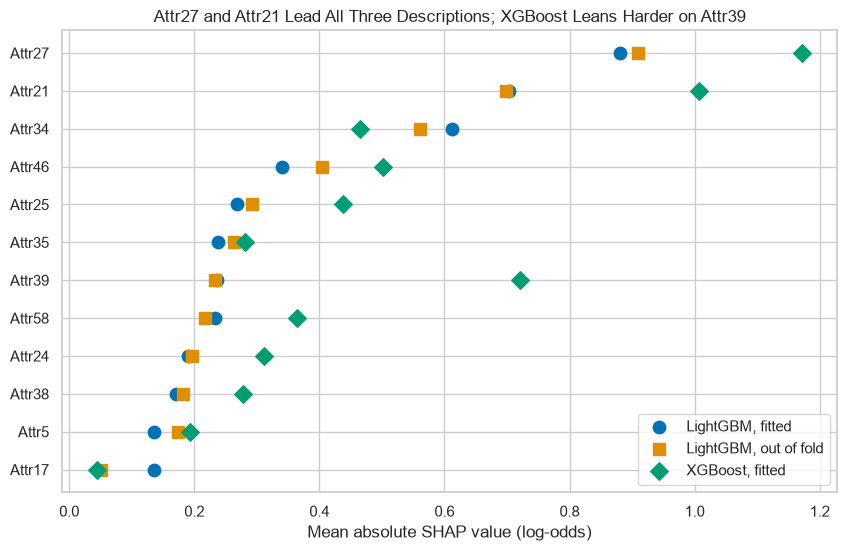

In [46]:
# the top 12 by LightGBM's mean absolute SHAP value under three descriptions, as dots on one scale
three = pd.DataFrame({"LightGBM, fitted": mean_abs, "LightGBM, out of fold": mean_abs_fold, "XGBoost, fitted": mean_abs_xgb}).loc[mean_abs.index[:12]]
print("Attr17:", three.loc["Attr17"].round(4).to_dict())
fig, ax = plt.subplots(figsize=(10, 6))
for name, marker in zip(three.columns, ["o", "s", "D"]):
    ax.scatter(three[name], three.index, s=80, marker=marker, label=name, zorder=3)
ax.set(xlabel="Mean absolute SHAP value (log-odds)", ylim=(11.6, -0.6))
ax.set_title("Attr27 and Attr21 Lead All Three Descriptions; XGBoost Leans Harder on Attr39")
ax.legend(loc="lower right")
plt.show()

LightGBM fitted and out of fold sit close for most columns; XGBoost leans more on `Attr27`, `Attr21` and `Attr39`.

`Attr17` falls from 0.1348 fitted to 0.0504 out of fold, the largest fall of the twelve, and XGBoost gives it 0.0451.

**On its own rows a booster describes what it memorised; a company's story needs rows the model never saw, while the column ranking holds.**

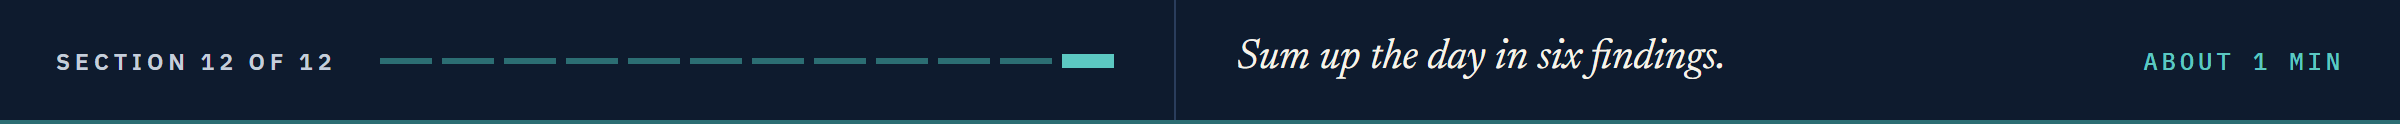

# Insights and Conclusion

A company's base value plus its SHAP values is its log-odds, to the 13th decimal place for LightGBM and about the 5th for XGBoost.

Contributions add in log-odds, not in points: the same 1.55 log-odds was a quarter of a point from the base value and eleven points near the top.

The model leans most on `Attr27`, `Attr21` and `Attr34`, an association in this file, and a gap in `Attr21` carries the largest contributions of all.

A near-copy column's credit goes to whichever column the trees used, and gain, split counts and SHAP each answer a different question.

Described on its own rows, the model tells memorised stories; out of fold the stories change and the ranking holds.

A SHAP value describes this model on these companies, never a reason for a bankruptcy or the effect of changing a ratio.

**The capstone describes its chosen model with SHAP values on the Taiwan file.**

> STORY: Scott Lundberg and Su-In Lee posted the paper that introduced SHAP values to arXiv on 22 May 2017, as 1705.07874. This note gives the paper's bibliography only. Source: https://arxiv.org/abs/1705.07874

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Compute SHAP values with `shap.TreeExplainer` and check that they add up to a booster's log-odds.
* Turn log-odds into a probability, and say why contributions stay in log-odds.
* Read a waterfall, a decision-path chart, a beeswarm, cohort bars and a dependence plot.
* Compare mean absolute SHAP values with gain and split counts, and spot a near-copy column.
* Describe companies with fold models that never saw them.

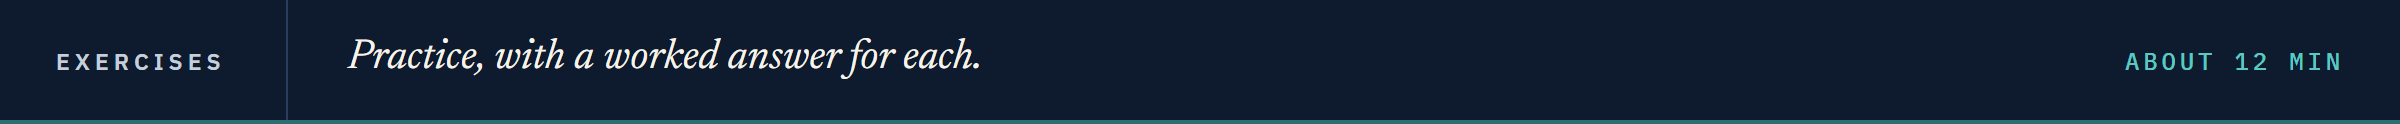

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**The Five Highest Outputs**

Q. Find the five companies with the highest output from `model`. For each, find the column with the largest SHAP value by size, and store the five column names, highest output first, in a list `ex1_columns`.

In [48]:
# your code here
ex1_columns = ...

In [49]:
check("Exercise 1 the largest contributions", ex1_columns, ["Attr21", "Attr21", "Attr21", "Attr21", "Attr21"])

Exercise 1 the largest contributions: not attempted yet


### Exercise 2

**SHAP Against Permutation Importance**

Q. Fit the booster on the first fold's four training folds, `next(folds.split(X_train, y_train))`, and run Day 4's `permutation_importance` on its held-out fold with `scoring="average_precision"`, `n_repeats=5`, `random_state=SEED` and `n_jobs=1`. Store how many of its top ten columns are in the top ten by mean absolute SHAP value in `ex2_shared`.

In [50]:
# your code here
ex2_shared = ...

In [51]:
check("Exercise 2 the columns shared", ex2_shared, 7)

Exercise 2 the columns shared: not attempted yet


### Exercise 3

**A Function for the Top Contributors**

Q. Write `top_contributors(explanation, position, k)` that returns the names of the `k` columns with the largest SHAP values by size for the company at that position, largest first. Store `top_contributors(shap_values, company, 3)` in `ex3_top`.

In [52]:
# your code here
ex3_top = ...

In [53]:
check("Exercise 3 the top three", ex3_top, ["Attr46", "Attr27", "Attr34"])

Exercise 3 the top three: not attempted yet


### Exercise 4: AI check

**The Probability That Hit 1.0**

You asked an AI assistant for a function that turns one company's SHAP values into the model's probability.
This came back.
It runs.
Test it, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def row_probability(explanation, position):
    # the base value plus the company's SHAP values, kept between 0 and 1 as a probability
    total = explanation.base_values[position] + explanation.values[position].sum()
    return float(np.clip(total, 0, 1))

ai_probability = row_probability(shap_values, company)
print("Probability:", ai_probability)

Probability: 1.0


In [55]:
# the test: the probability must match the model's own predict_proba for the same company
assert np.isclose(ai_probability, proba[company]), "not the model's probability: log-odds clipped to [0, 1]"

AssertionError: not the model's probability: log-odds clipped to [0, 1]

Q. Fix the function, and store its probability for `company` in `ex4_probability`.

In [56]:
# your code here
ex4_probability = ...

In [57]:
check("Exercise 4 the probability", ex4_probability, 0.9653848961587522)

Exercise 4 the probability: not attempted yet


## Congratulations!

You opened the model the desk kept and split one company's number into 64 contributions that add up exactly.
You saw why those contributions live in log-odds, walked forty companies from the base value, and read what the model leans on across the file.
You found a gap carrying the largest contributions, a near-copy column passing its credit sideways, and a company whose story changed on rows the model never saw.
Those are the questions a committee asks of any model, and you can now answer them with numbers.
In the capstone you choose a model for a new file and describe it the same way.

[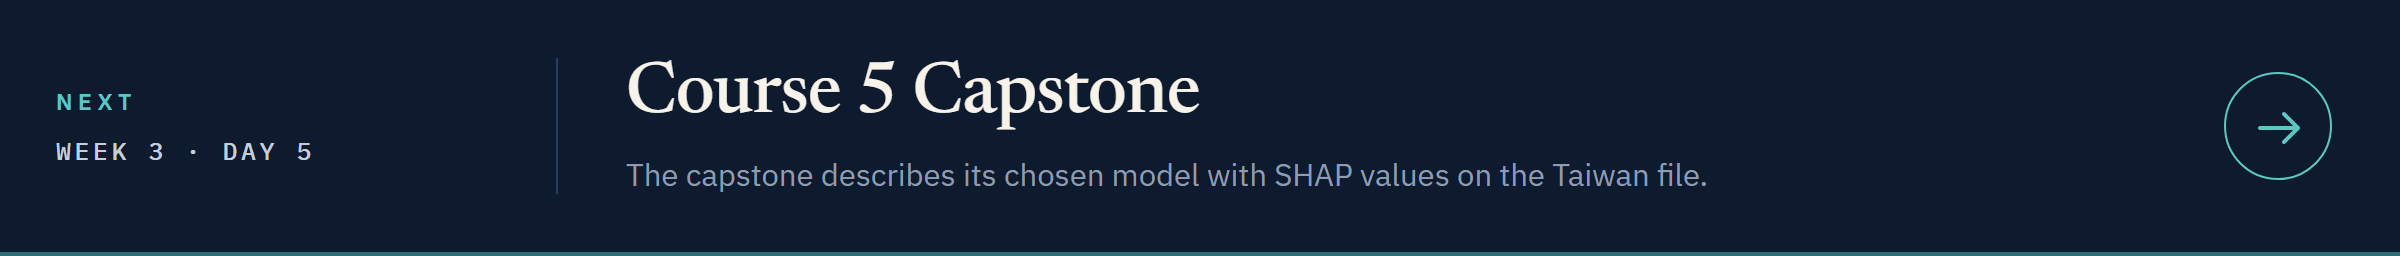](../day5/course5_capstone.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day5/course5_capstone.ipynb)